In [1]:
import sys
sys.path.append("./src")

import os

In [2]:
import warnings
warnings.filterwarnings("ignore")

In [3]:
from prosit.simulator import SimulatorParameters, SimulatorEngine

import pm4py
from pm4py.objects.log.importer.xes import importer as xes_importer
import pandas as pd

In [4]:
# import event log and Petri net model
# os.chdir('/home/padela/Scrivania/Fair-PrescriptiveProcessMonitoring/prosit-recommendations-simulator')
log = xes_importer.apply("../bpi12a.xes")
net, im, fm = pm4py.discover_petri_net_inductive(log, noise_threshold=0.1)

parsing log, completed traces ::   0%|          | 0/13087 [00:00<?, ?it/s]

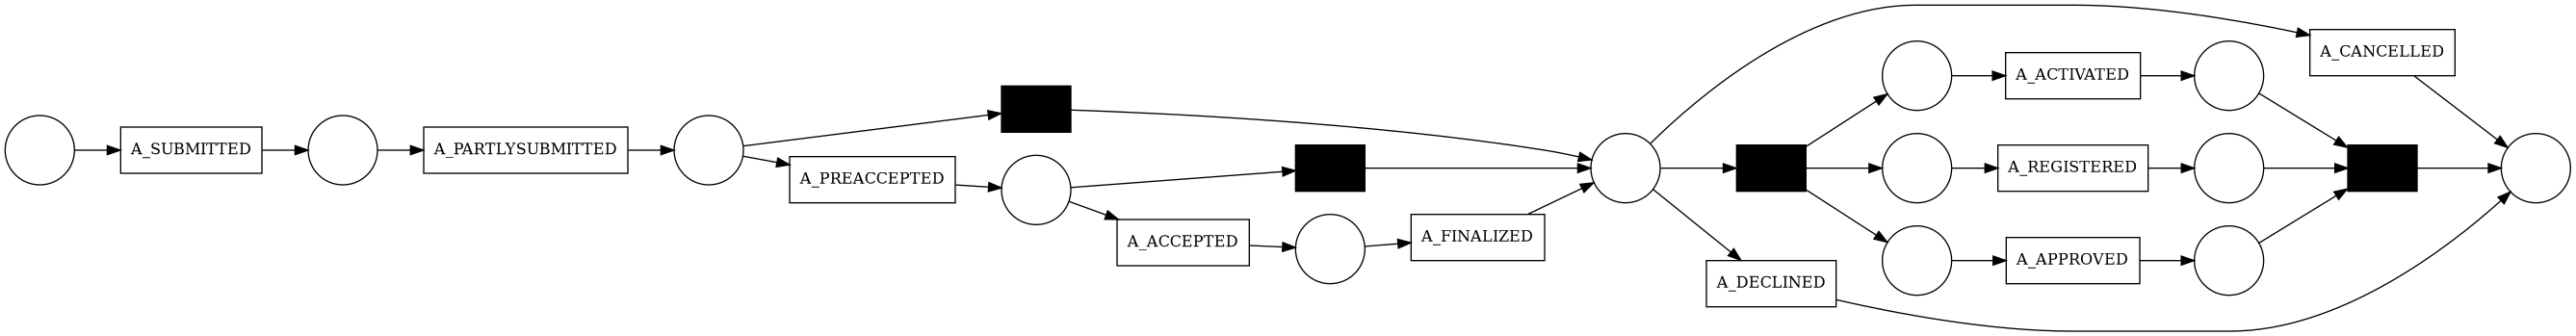

In [5]:
pm4py.view_petri_net(net)

In [6]:
pm4py.fitness_alignments(log, net, im, fm)

aligning log, completed variants ::   0%|          | 0/17 [00:00<?, ?it/s]

{'percFitTraces': 96.22526171009399,
 'averageFitness': 0.995025052123703,
 'percentage_of_fitting_traces': 96.22526171009399,
 'average_trace_fitness': 0.995025052123703,
 'log_fitness': 0.9950230737519067}

In [7]:
pm4py.precision_alignments(log, net, im, fm)
sim_params = SimulatorParameters(net, im, fm)
sim_params.discover_from_eventlog(log, max_depth_tree=0)

sim_engine = SimulatorEngine(sim_params)

computing precision with alignments, completed variants ::   0%|          | 0/14 [00:00<?, ?it/s]

Resources discovery...
Data attributes discovery...
Feature discovery...


aligning log, completed variants ::   0%|          | 0/17 [00:00<?, ?it/s]

100%|██████████| 13087/13087 [00:21<00:00, 607.98it/s]


Transition Probabilities discovery...
Calendars discovery...
Execution Time discovery...
Waiting Time discovery...
Arrival Time discovery...


In [8]:
# function for creating a recommendation DataFrame to use for simulation

def build_recommender_df(prev_log: pd.DataFrame, recommendations: dict) -> pd.DataFrame:

    prev_log["recommendation:act"] = None
    prev_log["recommendation:res"] = None 

    for case_id, recs in recommendations.items():
        act = recs.get("act", None)
        res = recs.get("res", None)
        last_index = prev_log[prev_log['case:concept:name'] == case_id].index[-1]
        prev_log.at[last_index, "recommendation:act"] = act
        prev_log.at[last_index, "recommendation:res"] = res
        
    return prev_log

In [9]:
# Create a random log with previous event (for test)
df_log = pm4py.convert_to_dataframe(log)

prev_log = pd.read_csv("/home/padela/Scrivania/Fair-PrescriptiveProcessMonitoring/experiments/bpi12_kappel/running_log.csv", index_col=0)
prev_log = prev_log[df_log.columns]

In [10]:
prev_log['case:concept:name'] = prev_log['case:concept:name'].astype(str)
prev_log['time:timestamp'] = pd.to_datetime(prev_log['time:timestamp'], format="mixed")
prev_log['start:timestamp'] = pd.to_datetime(prev_log['start:timestamp'], format="mixed")

In [11]:
def compute_activity_resource_probabilities(
    event_log,
    activity_col='concept:name',
    resource_col='org:resource'):
    """
    Compute resource probability distributions per activity.

    Returns
    -------
    dict
        Mapping:
        {
            <activity>: [(<resource_1>, <prob_1>), (<resource_2>, <prob_2>), ...]
        }
    """
    if activity_col not in event_log.columns:
        raise ValueError(f"Column '{activity_col}' not found in event_log.")
    if resource_col not in event_log.columns:
        raise ValueError(f"Column '{resource_col}' not found in event_log.")

    df = event_log[[activity_col, resource_col]].dropna()
    if df.empty:
        return {}

    # Frequency table and normalized probabilities per activity.
    counts = (
        df.groupby([activity_col, resource_col])
        .size()
        .rename('count')
        .reset_index()
    )
    counts['probability'] = counts.groupby(activity_col)['count'].transform(
        lambda x: x / x.sum()
    )

    distributions = {}
    for activity, group in counts.groupby(activity_col):
        group_sorted = group.sort_values('probability', ascending=False)
        distributions[activity] = [
            (row[resource_col], float(row['probability']))
            for _, row in group_sorted.iterrows()
        ]

    return distributions

In [18]:
base_dir = "/home/padela/Scrivania/Fair-PrescriptiveProcessMonitoring/recc_activities_bpi12"
sim_dir = os.path.join(base_dir, "simulated_logs")
os.makedirs(sim_dir, exist_ok=True)

resources_prob = compute_activity_resource_probabilities(df_log)
rec_files = [
    f for f in os.listdir(base_dir)
    if f.endswith(".csv") and "recommended_activities" in f
]

simulated_log_paths = {}

for rec_file in rec_files:
    rec_path = os.path.join(base_dir, rec_file)
    rec_df = pd.read_csv(rec_path)

    recommendations = {}
    prev_log2 = prev_log.copy()
    prev_log2["case:concept:name"] = prev_log2["case:concept:name"].astype(str)
    valid_cases = set(prev_log2["case:concept:name"].unique())

    for _, row in rec_df.iterrows():
        raw_case_id = row.get("case:concept:name", row.get("case_id"))
        raw_act = row.get("concept:name", row.get("activity"))

        if pd.isna(raw_case_id) or pd.isna(raw_act):
            continue

        case_id = str(raw_case_id)
        if case_id not in valid_cases:
            continue

        resource_distribution = resources_prob.get(raw_act, [])
        most_probable_resource = resource_distribution[0][0] if resource_distribution else None
        recommendations[case_id] = {"act": raw_act, "res": most_probable_resource}

    log_rec = build_recommender_df(prev_log2, recommendations)
    sim_log = sim_engine.apply(prev_log=log_rec)

    out_name = f"{os.path.splitext(rec_file)[0]}_simulated.csv"
    out_path = os.path.join(sim_dir, out_name)
    sim_log.to_csv(out_path, index=False)
    simulated_log_paths[rec_file] = out_path

Simulating Cases: 2617it [00:01, 2509.39it/s]                          
Simulating Cases: 2617it [00:01, 2491.51it/s]                          
Simulating Cases: 2617it [00:01, 2571.67it/s]                          
Simulating Cases: 2617it [00:01, 1661.73it/s]                          
Simulating Cases: 2617it [00:01, 1905.13it/s]                          
Simulating Cases: 2617it [00:01, 2413.38it/s]                          


In [ ]:
# Mean trace duration (days) per simulated log type + original BPI12 log
mean_trace_duration_days = {}

for rec_file, sim_path in simulated_log_paths.items():
    sim_df = pd.read_csv(sim_path)
    sim_df["time:timestamp"] = pd.to_datetime(sim_df["time:timestamp"], errors="coerce")

    trace_durations = sim_df.groupby("case:concept:name")["time:timestamp"].agg(["min", "max"])
    trace_durations_days = (trace_durations["max"] - trace_durations["min"]).dt.total_seconds() / (24 * 3600)

    log_type = os.path.splitext(rec_file)[0]
    mean_trace_duration_days[log_type] = (float(trace_durations_days.mean()), float(trace_durations_days.std()))

# Evaluate the original dataset in data/bpi12.pkl
bpi12_df = pd.read_pickle("/home/padela/Scrivania/Fair-PrescriptiveProcessMonitoring/data/bpi12.pkl")
case_col = "case:concept:name" if "case:concept:name" in bpi12_df.columns else "case_id"
bpi12_df["time:timestamp"] = pd.to_datetime(bpi12_df["time:timestamp"], errors="coerce")

bpi12_trace_durations = bpi12_df.groupby(case_col)["time:timestamp"].agg(["min", "max"])
bpi12_trace_durations_days = (bpi12_trace_durations["max"] - bpi12_trace_durations["min"]).dt.total_seconds() / (24 * 3600)
mean_trace_duration_days["bpi12"] = float(bpi12_trace_durations_days.mean())

mean_trace_duration_days

{'bpi12_kappel_LTN_recommended_activities_counterfactual': 4.229462621277898,
 'bpi12_kappel_LTN_Fairness_recommended_activities': 4.25378511268469,
 'bpi12_kappel_LTN_recommended_activities': 4.1979692558317065,
 'bpi12_kappel_LSTM_recommended_activities': 5.940781816585644,
 'bpi12_kappel_LSTM_recommended_activities_counterfactual': 5.434202873590059,
 'bpi12_kappel_LTN_Fairness_recommended_activities_counterfactual': 4.039311044988077,
 'bpi12': 8.077909500702564}

In [14]:
sim_log[sim_log['case:concept:name']=='206630']

,case:concept:name,concept:name,org:resource,start:timestamp,time:timestamp,case:AMOUNT_REQ
362,206630,A_SUBMITTED,112,2012-02-05 18:34:40.716000+00:00,2012-02-05 18:34:40.716000+00:00,7000
363,206630,A_PARTLYSUBMITTED,112,2012-02-05 18:34:40.716000+00:00,2012-02-05 18:34:41.218000+00:00,7000
364,206630,A_CANCELLED,112,2012-02-05 18:34:41.218000+00:00,2012-02-21 23:37:41.218000+00:00,7000


In [15]:
log_rec[log_rec['case:concept:name']=='206630']

,concept:name,org:resource,time:timestamp,start:timestamp,case:concept:name,case:AMOUNT_REQ,recommendation:act,recommendation:res
296,A_SUBMITTED,112,2012-02-05 18:34:40.716000+00:00,2012-02-05 18:34:40.716000+00:00,206630,7000,None,None
297,A_PARTLYSUBMITTED,112,2012-02-05 18:34:41.218000+00:00,2012-02-05 18:34:40.716000+00:00,206630,7000,A_CANCELLED,112


In [16]:
log_rec['case:concept:name'].unique()[101]

'206630'

In [17]:
# Calcola e stampa i tempi medi di esecuzione (end - start) per ogni attività ("concept:name")

acts = o_log['activity'].unique()
for a in acts:
    o_log_a = o_log[o_log['activity'] == a]
    # mean_t_a = (o_log_a['time:timestamp'] - o_log_a['start:timestamp']).mean()
    mean_t_a = o_log_a['time_delta'].mean()
    print(a, ' ---> ', mean_t_a)

NameError: name 'o_log' is not defined

In [ ]:
# Calcola e stampa i tempi medi di esecuzione (end - start) per ogni attività ("concept:name")

acts = g_log['concept:name'].unique()
g_log['time:timestamp'] = pd.to_datetime(g_log['time:timestamp'], format="mixed")
g_log['start:timestamp'] = pd.to_datetime(g_log['start:timestamp'], format="mixed")

for a in acts:
    g_log_a = g_log[g_log['concept:name'] == a]
    mean_t_a = (g_log_a['time:timestamp'] - g_log_a['start:timestamp']).mean()
    # mean_t_a = o_log_a['time_delta'].mean()
    print(a, ' ---> ', mean_t_a.total_seconds())

A_SUBMITTED  --->  0.0
A_PARTLYSUBMITTED  --->  0.577918
A_CANCELLED  --->  2580076.170731
A_PREACCEPTED  --->  8018.402078
A_ACCEPTED  --->  64835.978879
A_FINALIZED  --->  6691.775232
A_ACTIVATED  --->  273097.185747
A_DECLINED  --->  377849.735849
A_REGISTERED  --->  381517.143016
A_APPROVED  --->  515762.663236
